In [9]:
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
from collections import Counter
import pandas as pd
from math import exp
import numpy as np
from functools import reduce
from pathlib import Path

In [10]:
folder = Path("C:/Users/Ognjen/axl_mab/Axelrod/axelrod/optimization/exceli")
pattern = "**/*"
extensions = {".xlsx", ".xlsm", ".xls"}

results = {}
for file in sorted(folder.glob(pattern)):
    if file.suffix.lower() not in extensions or file.name.startswith("~$"):
        continue
    try:
        df = pd.read_excel(file, sheet_name="FINAL")
        df["source_file"] = file.name  # keep track of where each row came from
        results[file.name.replace(".xlsx", "").replace("Axelrod-", "")] = df
    except ValueError:
        print(f"Skipping {file.name}: sheet 'FINAL' not found.")
    except Exception as e:
        print(f"Error in {file.name}: {e}")
    

In [11]:
algorithm_ranks = []

for algorithm in results:
    df = results[algorithm]
    row = df[df["Name"] == algorithm]
    idx = row.index[0]+1
    avg_score = row["AvgScore"].iloc[0]

    algorithm_ranks.append((algorithm, idx, avg_score))


In [12]:
results = {}
for file in sorted(folder.glob(pattern)):
    if file.suffix.lower() not in extensions or file.name.startswith("~$"):
        continue

    algo_name = file.stem.replace("Axelrod-", "")  # stem = name without extension
    results[algo_name] = []

    for i in range(1, 31):
        df = pd.read_excel(file, sheet_name=f"Rank_List_{i}")
        row = df[df["Name"] == algo_name]
        if row.empty:
            results[algo_name].append(None)  # keeps the position aligned with i
        else:
            results[algo_name].append(row["TotalScore"].iloc[0]/226)

In [13]:
print(results)

{'FuzzyMamdaniGA': [576.141592920354, 578.8716814159292, 585.5486725663717, 585.6017699115044, 582.7477876106195, 582.6858407079646, 576.2433628318585, 580.7256637168142, 582.0353982300885, 576.570796460177, 575.8849557522124, 575.4690265486726, 580.0088495575221, 576.8318584070796, 579.6504424778761, 582.1283185840708, 578.3230088495575, 581.4115044247787, 578.8805309734513, 581.7522123893805, 578.9115044247787, 580.8053097345132, 575.9734513274336, 580.5752212389381, 576.1283185840708, 580.3407079646017, 583.6150442477876, 581.2743362831858, 575.9955752212389, 581.5], 'FuzzyMamdaniO': [576.3539823008849, 578.8318584070796, 579.3805309734513, 576.3008849557522, 577.787610619469, 579.2964601769911, 576.5530973451328, 576.6946902654868, 582.1769911504425, 579.9247787610619, 575.358407079646, 583.1814159292036, 581.6814159292036, 579.6548672566372, 584.7566371681415, 579.2035398230089, 577.3451327433628, 582.2389380530974, 580.1725663716815, 581.7522123893805, 580.0, 579.8893805309734, 5

In [14]:
df = pd.DataFrame.from_dict(
    results, orient="index",
    columns=[f"Iteration_{i}" for i in range(1, 31)]
)
df.index.name = "Algorithm"

df.to_excel("all_algorithms.xlsx", sheet_name="TotalScore")

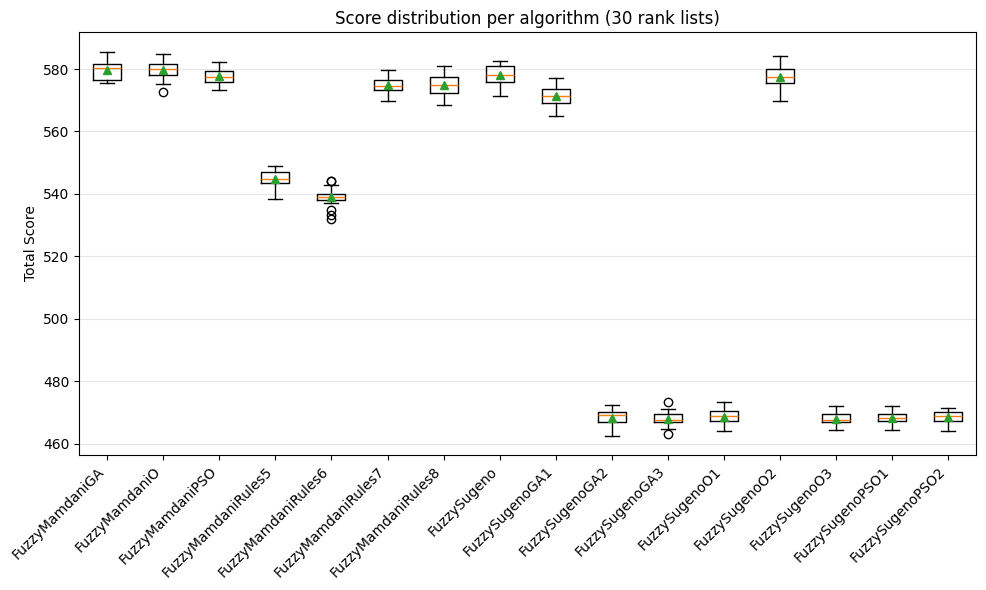

In [15]:
labels = list(results.keys())
data = list(results.values())

fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot(data, tick_labels=labels, showmeans=True)  # use labels=labels on matplotlib < 3.9

ax.set_ylabel("Total Score")
ax.set_title("Score distribution per algorithm (30 rank lists)")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()